In [1]:
import pandas as pd
import numpy as np
import re
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc

from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import StackingClassifier

In [2]:
train_df = pd.read_csv("train.csv")
hate_df = pd.read_csv("labeled_data.csv")

In [4]:
print("Train Info:\n")
print(train_df.info())

print("\nTrain Head:\n")
print(train_df.head())

print("\nHate Dataset Info:\n")
print(hate_df.info())
print("\nHate Head:\n")
print(hate_df.head())

Train Info:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype 
---  ------         --------------   ----- 
 0   id             159571 non-null  object
 1   comment_text   159571 non-null  object
 2   toxic          159571 non-null  int64 
 3   severe_toxic   159571 non-null  int64 
 4   obscene        159571 non-null  int64 
 5   threat         159571 non-null  int64 
 6   insult         159571 non-null  int64 
 7   identity_hate  159571 non-null  int64 
dtypes: int64(6), object(2)
memory usage: 9.7+ MB
None

Train Head:

                 id                                       comment_text  toxic  \
0  0000997932d777bf  Explanation\nWhy the edits made under my usern...      0   
1  000103f0d9cfb60f  D'aww! He matches this background colour I'm s...      0   
2  000113f07ec002fd  Hey man, I'm really not trying to edit war. It...      0   
3  0001b41b1c6bb37e  "\nMore\nI can't make a

In [5]:
print("\nMissing Values:\n")
print(train_df.isnull().sum())


Missing Values:

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64


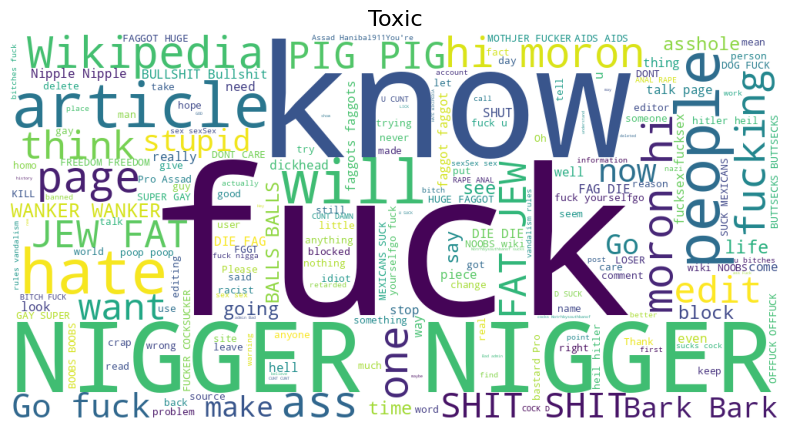

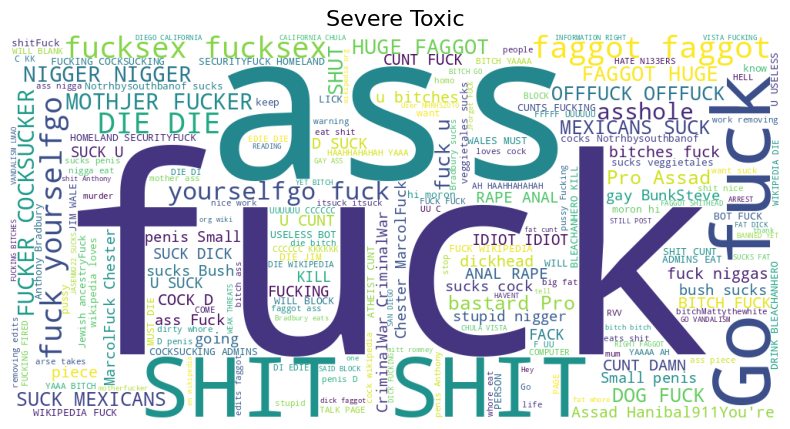

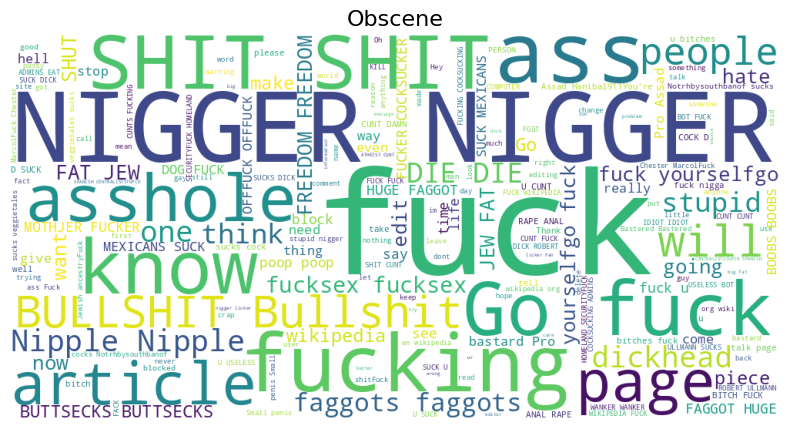

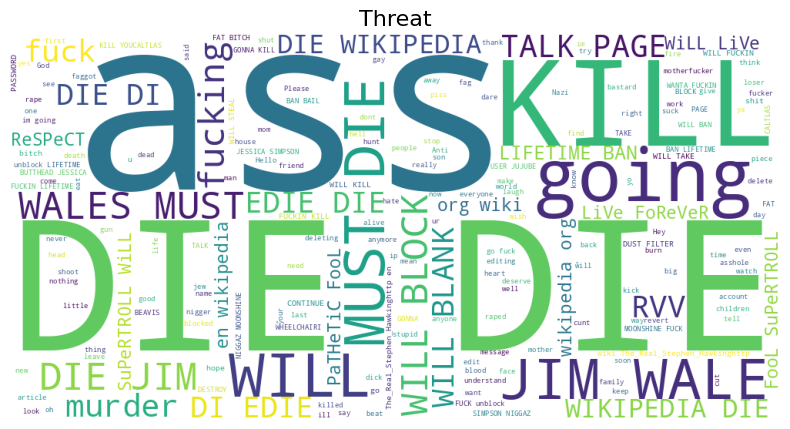

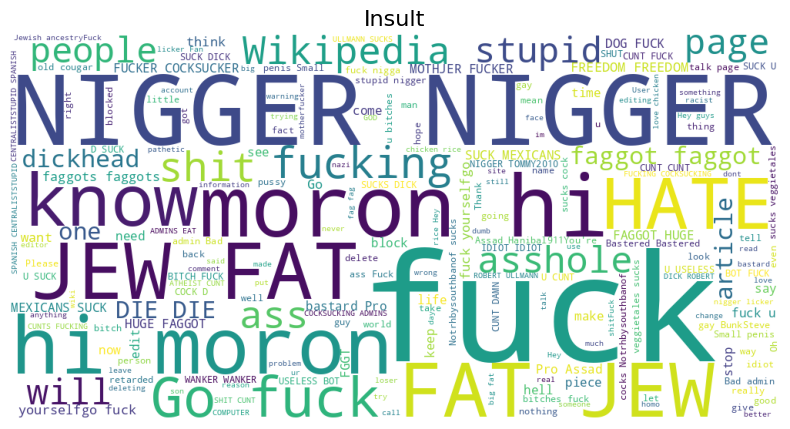

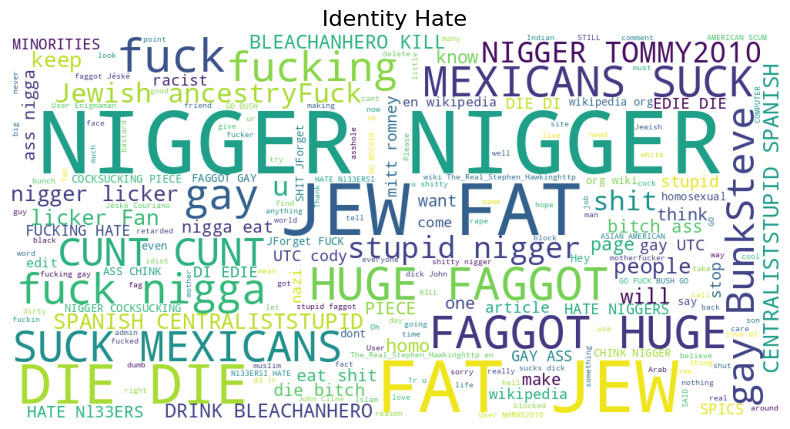

In [14]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

labels = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]

for label in labels:
    text = " ".join(train_df[train_df[label] == 1]["comment_text"].dropna())

    wc = WordCloud(
        width=1000,
        height=500,
        background_color="white"
    ).generate(text)

    plt.figure(figsize=(10,5))  # each plot gets full space
    plt.imshow(wc)
    plt.title(label.replace("_", " ").title(), fontsize=16)
    plt.axis("off")
    plt.show()

In [16]:
train_df.rename(columns={"comment_text": "text"}, inplace=True)

train_df["label"] = (
    train_df[["toxic","severe_toxic","obscene","threat","insult","identity_hate"]]
    .max(axis=1)
    .apply(lambda x: "unsafe" if x == 1 else "safe")
)

train_df = train_df[["text", "label"]]
train_df = train_df.dropna()

In [17]:
hate_df.rename(columns={"tweet": "text"}, inplace=True)

hate_df = hate_df[hate_df["class"].isin([0,2])]

hate_df["label"] = hate_df["class"].map({
    0: "unsafe",
    2: "safe"
})

hate_df = hate_df[["text", "label"]]

/tmp/ipykernel_6650/1639420720.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hate_df["label"] = hate_df["class"].map({


In [18]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"@\w+", "", text)
    text = re.sub(r"#", "", text)
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

train_df["text"] = train_df["text"].apply(clean_text)
hate_df["text"] = hate_df["text"].apply(clean_text)

label
safe      147509
unsafe     17655
Name: count, dtype: int64


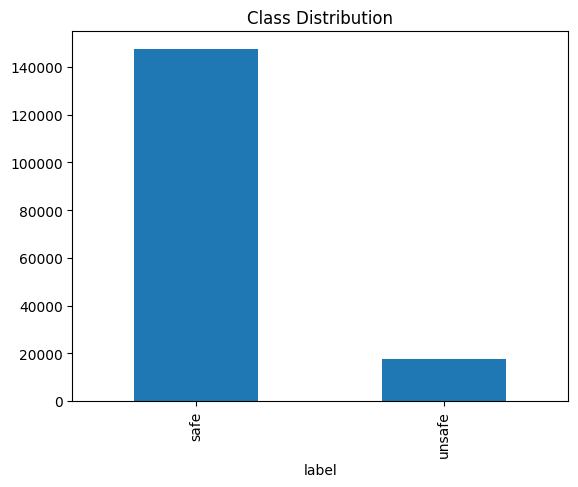

In [21]:
combined_df = pd.concat([train_df, hate_df])
print(combined_df['label'].value_counts())
combined_df["label"].value_counts().plot(kind="bar")
plt.title("Class Distribution")
plt.show()

In [20]:
combined_df = combined_df.sample(frac=1, random_state=42)

X = combined_df["text"]
y = combined_df["label"]

In [22]:
vectorizer = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1,2),
    min_df=3
)

X_train = vectorizer.fit_transform(X)
y_train = y

In [24]:
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# =========================
# 🔹 DEFINE MODELS (WITH CLASS IMBALANCE FIX)
# =========================
models = {
    "Logistic Regression": LogisticRegression(max_iter=300, class_weight="balanced"),
    "SVM": LinearSVC(class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "SGD": SGDClassifier(loss="log_loss", class_weight="balanced")
}

In [26]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import make_scorer, recall_score

# Stratified CV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 🔥 Custom scorer → focus on unsafe recall
unsafe_recall = make_scorer(recall_score, pos_label="unsafe")

cv_results = {}

print("🔁 Cross Validation Results (Unsafe Recall Focus):\n")

for name, m in models.items():
    print(f"\n================ {name} ================")

    # 🔹 Recall (unsafe)
    recall_scores = cross_val_score(
        m,
        X_train,
        y_train,
        cv=skf,
        scoring=unsafe_recall,
        n_jobs=-1
    )

    # 🔹 F1 (for balance)
    f1_scores = cross_val_score(
        m,
        X_train,
        y_train,
        cv=skf,
        scoring="f1_weighted",
        n_jobs=-1
    )

    cv_results[name] = {
        "recall": recall_scores,
        "f1": f1_scores
    }

    print("Recall (unsafe):", recall_scores)
    print("Mean Recall:", round(recall_scores.mean(), 4))

    print("F1 Scores:", f1_scores)
    print("Mean F1:", round(f1_scores.mean(), 4))

🔁 Cross Validation Results (Unsafe Recall Focus):


================ Logistic Regression ================
Recall (unsafe): [0.8603795  0.8558482  0.86151232 0.85386576 0.85499858]
Mean Recall: 0.8573
F1 Scores: [0.93807045 0.93649896 0.93827204 0.93483133 0.93686198]
Mean F1: 0.9369

================ SVM ================
Recall (unsafe): [0.82922685 0.81903144 0.82441235 0.82101388 0.82639479]
Mean Recall: 0.824
F1 Scores: [0.93837601 0.93587114 0.9369368  0.93512233 0.93677267]
Mean F1: 0.9366

================ Naive Bayes ================
Recall (unsafe): [0.5627301  0.56442934 0.57037666 0.5579156  0.56584537]
Mean Recall: 0.5643
F1 Scores: [0.93981757 0.94032928 0.94141924 0.93971901 0.94085713]
Mean F1: 0.9404

================ SGD ================
Recall (unsafe): [0.84961767 0.83970547 0.8462192  0.84027188 0.83602379]
Mean Recall: 0.8424
F1 Scores: [0.91914567 0.91493218 0.9189016  0.91618874 0.91876579]
Mean F1: 0.9176


In [27]:
test_df = pd.read_csv("test.csv")
labels_df = pd.read_csv("test_labels.csv")

test_df.rename(columns={"comment_text": "text"}, inplace=True)

df = test_df.merge(labels_df, on="id")

# Remove invalid rows
df = df[df["toxic"] != -1]

In [28]:
label_cols = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]

df["actual"] = df[label_cols].max(axis=1)
df["actual"] = df["actual"].apply(lambda x: "unsafe" if x == 1 else "safe")

df["text"] = df["text"].apply(clean_text)

X_test = vectorizer.transform(df["text"])

In [31]:
trained_models = {}
results = {}

for name, m in models.items():
    print(f"\n================ {name} ================")

    m.fit(X_train, y_train)
    trained_models[name] = m

    if name == "Logistic Regression":
        probs = m.predict_proba(X_test)
        y_pred = ["unsafe" if p[1] > 0.75 else "safe" for p in probs]
    else:
        y_pred = m.predict(X_test)

    print(classification_report(df["actual"], y_pred))

    results[name] = classification_report(df["actual"], y_pred, output_dict=True)


================ Logistic Regression ================
              precision    recall  f1-score   support

        safe       0.98      0.93      0.95     57735
      unsafe       0.55      0.80      0.65      6243

    accuracy                           0.92     63978
   macro avg       0.76      0.86      0.80     63978
weighted avg       0.94      0.92      0.92     63978


================ SVM ================
              precision    recall  f1-score   support

        safe       0.99      0.88      0.93     57735
      unsafe       0.44      0.88      0.58      6243

    accuracy                           0.88     63978
   macro avg       0.71      0.88      0.76     63978
weighted avg       0.93      0.88      0.89     63978


================ Naive Bayes ================
              precision    recall  f1-score   support

        safe       0.96      0.97      0.96     57735
      unsafe       0.68      0.58      0.63      6243

    accuracy                           0.

In [32]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=300, class_weight="balanced")),
        ("nb", MultinomialNB()),
        ("sgd", SGDClassifier(loss="log_loss", class_weight="balanced"))
    ],
    final_estimator=LogisticRegression()
)

stack.fit(X_train, y_train)

y_pred = stack.predict(X_test)

print("\nSTACKING MODEL:\n")
print(classification_report(df["actual"], y_pred))

results["Stacking"] = classification_report(df["actual"], y_pred, output_dict=True)


STACKING MODEL:

              precision    recall  f1-score   support

        safe       0.98      0.93      0.95     57735
      unsafe       0.55      0.80      0.65      6243

    accuracy                           0.92     63978
   macro avg       0.76      0.86      0.80     63978
weighted avg       0.94      0.92      0.92     63978



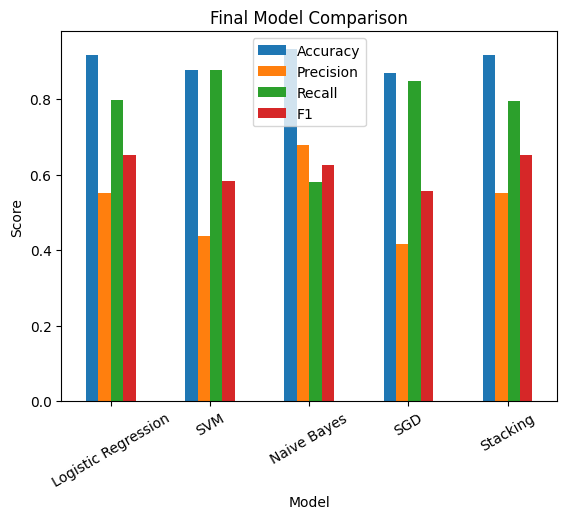

In [36]:
comparison = []

for model_name, report in results.items():
    comparison.append({
        "Model": model_name,
        "Accuracy": report["accuracy"],
        "Precision": report["unsafe"]["precision"],
        "Recall": report["unsafe"]["recall"],
        "F1": report["unsafe"]["f1-score"]
    })

comparison_df = pd.DataFrame(comparison)

comparison_df.set_index("Model").plot(kind="bar")
plt.title("Final Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.show()

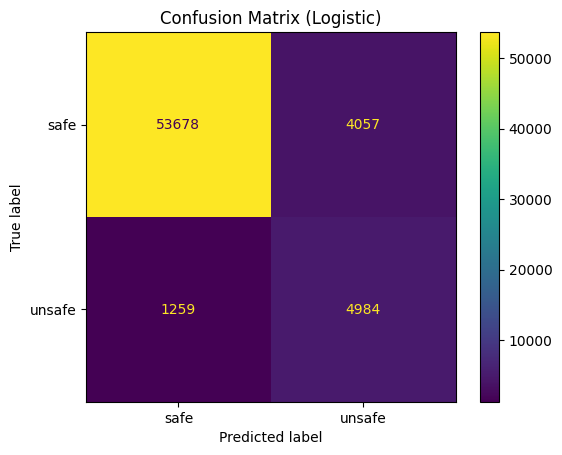

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model = trained_models["Logistic Regression"]

probs = model.predict_proba(X_test)
y_pred = ["unsafe" if p[1] > 0.75 else "safe" for p in probs]

cm = confusion_matrix(df["actual"], y_pred, labels=["safe","unsafe"])

disp = ConfusionMatrixDisplay(cm, display_labels=["safe","unsafe"])
disp.plot()
plt.title("Confusion Matrix (Logistic)")
plt.show()

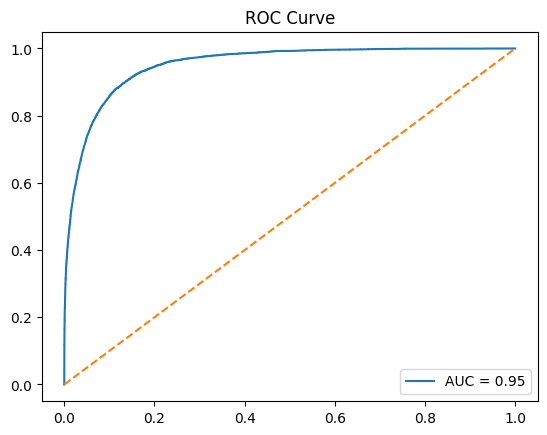

In [38]:
from sklearn.metrics import roc_curve, auc

y_true = df["actual"].map({"safe":0,"unsafe":1})

probs = model.predict_proba(X_test)[:,1]

fpr, tpr, _ = roc_curve(y_true, probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1],[0,1],'--')

plt.title("ROC Curve")
plt.legend()
plt.show()

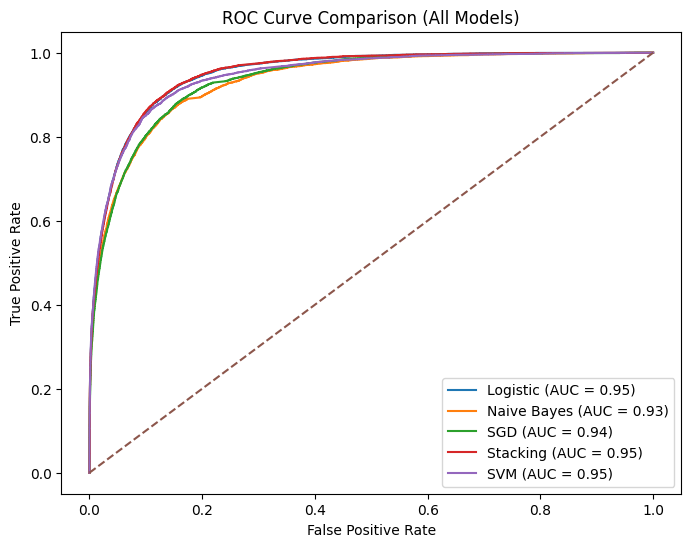

In [45]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Convert labels
y_true = df["actual"].map({"safe":0,"unsafe":1})

plt.figure(figsize=(8,6))

# =========================
# 🔹 Logistic Regression
# =========================
lr_probs = trained_models["Logistic Regression"].predict_proba(X_test)[:,1]
fpr_lr, tpr_lr, _ = roc_curve(y_true, lr_probs)
auc_lr = auc(fpr_lr, tpr_lr)

plt.plot(fpr_lr, tpr_lr, label=f"Logistic (AUC = {auc_lr:.2f})")


# =========================
# 🔹 Naive Bayes
# =========================
nb_probs = trained_models["Naive Bayes"].predict_proba(X_test)[:,1]
fpr_nb, tpr_nb, _ = roc_curve(y_true, nb_probs)
auc_nb = auc(fpr_nb, tpr_nb)

plt.plot(fpr_nb, tpr_nb, label=f"Naive Bayes (AUC = {auc_nb:.2f})")


# =========================
# 🔹 SGD
# =========================
sgd_probs = trained_models["SGD"].predict_proba(X_test)[:,1]
fpr_sgd, tpr_sgd, _ = roc_curve(y_true, sgd_probs)
auc_sgd = auc(fpr_sgd, tpr_sgd)

plt.plot(fpr_sgd, tpr_sgd, label=f"SGD (AUC = {auc_sgd:.2f})")


# =========================
# 🔹 Stacking
# =========================
stack_probs = stack.predict_proba(X_test)[:,1]
fpr_stack, tpr_stack, _ = roc_curve(y_true, stack_probs)
auc_stack = auc(fpr_stack, tpr_stack)

plt.plot(fpr_stack, tpr_stack, label=f"Stacking (AUC = {auc_stack:.2f})")


# =========================
# 🔹 SVM (using decision_function)
# =========================
svm_scores = trained_models["SVM"].decision_function(X_test)
fpr_svm, tpr_svm, _ = roc_curve(y_true, svm_scores)
auc_svm = auc(fpr_svm, tpr_svm)

plt.plot(fpr_svm, tpr_svm, label=f"SVM (AUC = {auc_svm:.2f})")


# =========================
# 🔹 Random baseline
# =========================
plt.plot([0,1],[0,1],'--')


# =========================
# 🔹 Final plot
# =========================
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (All Models)")
plt.legend()
plt.show()

In [50]:
# =========================
# Collect AUC values
# =========================
auc_scores = {
    "Logistic": auc_lr,
    "Naive Bayes": auc_nb,
    "SGD": auc_sgd,
    "Stacking": auc_stack,
    "SVM": auc_svm
}

print("AUC Scores:", auc_scores)

AUC Scores: {'Logistic': np.float64(0.9519542851013834), 'Naive Bayes': np.float64(0.9343324424628643), 'SGD': np.float64(0.936637888336383), 'Stacking': np.float64(0.9519528535161943), 'SVM': np.float64(0.9463671257768691)}


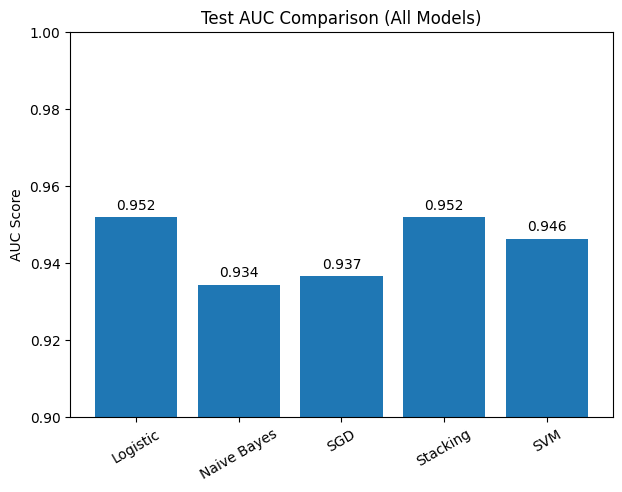

In [51]:
import matplotlib.pyplot as plt

models = list(auc_scores.keys())
values = list(auc_scores.values())

plt.figure(figsize=(7,5))
plt.bar(models, values)

plt.title("Test AUC Comparison (All Models)")
plt.ylabel("AUC Score")
plt.ylim(0.90, 1.0)  # zoom for clarity
plt.xticks(rotation=30)

# Add values on top
for i, v in enumerate(values):
    plt.text(i, v + 0.002, f"{v:.3f}", ha='center')

plt.show()

In [54]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# =========================
# 🔹 DEFINE MODELS (WITH CLASS IMBALANCE FIX)
# =========================
models = {
    "Logistic Regression": LogisticRegression(max_iter=300, class_weight="balanced"),
    "SVM": LinearSVC(class_weight="balanced"),
    "Naive Bayes": MultinomialNB(),
    "SGD": SGDClassifier(loss="log_loss", class_weight="balanced")
}
auc_results = {}

print("🔁 Cross-Validation AUC Results:\n")

for name, m in models.items():
    print(f"\n================ {name} ================")

    scores = cross_val_score(
        m,
        X_train,
        y_train,
        cv=5,
        scoring="roc_auc",
        n_jobs=-1
    )

    auc_results[name] = scores

    print("AUC Scores:", scores)
    print("Mean AUC:", round(scores.mean(), 4))
    print("Std Dev:", round(scores.std(), 4))   # 🔥 added (important)

🔁 Cross-Validation AUC Results:


================ Logistic Regression ================
AUC Scores: [0.96723514 0.96483702 0.96551391 0.96814419 0.96716949]
Mean AUC: 0.9666
Std Dev: 0.0012

================ SVM ================
AUC Scores: [0.95778025 0.95539023 0.95539983 0.96039736 0.95727242]
Mean AUC: 0.9572
Std Dev: 0.0018

================ Naive Bayes ================
AUC Scores: [0.94888565 0.94615039 0.94873159 0.95022801 0.95028158]
Mean AUC: 0.9489
Std Dev: 0.0015

================ SGD ================
AUC Scores: [0.95236158 0.95137693 0.95168246 0.95415187 0.95324894]
Mean AUC: 0.9526
Std Dev: 0.001
